# Cookie Cats: Oyun İçi Bekleme Kapısının Yerini Değiştirmek Retention'ı Etkiler mi?

**İş sorusu:** Mobil bulmaca oyunu Cookie Cats'te oyuncular belirli bir seviyeye gelince bir "kapı" ile karşılaşır: ya bir süre bekler ya da ödeme yapar. Kapı şu an 30. seviyede. Ürün ekibi kapıyı 40. seviyeye taşımayı düşünüyor. Böylece oyuncunun oyunu daha uzun süre kesintisiz oynayacağını ve bağlılığının artacağını varsayıyor.

**Deney:** Yeni oyuncular rastgele iki gruba ayrıldı:
- `gate_30` (kontrol): kapı 30. seviyede
- `gate_40` (test): kapı 40. seviyede

**Karar:** Kapı 40. seviyeye taşınmalı mı?

**Veri:** 90.189 oyuncu. Her satır bir oyuncu: grubu, ilk 14 günde oynadığı tur sayısı, kurulumdan 1 gün ve 7 gün sonra oyuna dönüp dönmediği.

**Araçlar:** Python (pandas, SciPy, statsmodels, matplotlib)

**Bölümler**
1. Veriyi tanıma ve temizleme
2. Deney sağlık kontrolü (SRM)
3. Testin gücü: hangi farkı yakalayabiliriz?
4. 1. gün retention
5. 7. gün retention
6. Bootstrap ile doğrulama
7. Oyun turu sayısı (engagement)
8. Keşifsel: kapıya ulaşan oyuncular
9. İş etkisi
10. Sonuç ve karar

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.power import NormalIndPower

if Path.cwd().name == "notebooks":
    os.chdir("..")
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9893"
RENK = {"gate_30": BLUE, "gate_40": ORANGE}
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
ALFA = 0.05
results = {}

---
## 1. Veriyi tanıma ve temizleme

**Neden:** Analiz öncesi her oyuncunun bir kez yer aldığından ve aykırı değerlerin sonucu bozmayacağından emin olmalıyız.

**Nasıl:** Tekrar eden oyuncu, eksik değer ve tur sayısı dağılımına bakıyoruz.

In [2]:
df = pd.read_csv("data/cookie_cats.csv")
print(f"Satır: {len(df):,} | Tekil oyuncu: {df.userid.nunique():,} | Eksik değer: {df.isna().sum().sum()}")
df.head()

Satır: 90,189 | Tekil oyuncu: 90,189 | Eksik değer: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.sum_gamerounds.describe(percentiles=[0.25, 0.5, 0.75, 0.99, 0.999])

count   90,189.0000
mean        51.8725
std        195.0509
min          0.0000
25%          5.0000
50%         16.0000
75%         51.0000
99%        493.0000
99.9%    1,073.6240
max     49,854.0000
Name: sum_gamerounds, dtype: float64

In [4]:
print("En yüksek 5 tur sayısı:", df.sum_gamerounds.nlargest(5).tolist())
print(f"Hiç oynamayan (0 tur) oyuncu: %{100*(df.sum_gamerounds == 0).mean():.1f}")

En yüksek 5 tur sayısı: [49854, 2961, 2640, 2438, 2294]
Hiç oynamayan (0 tur) oyuncu: %4.4


In [5]:
aykiri = df.sum_gamerounds.idxmax()
print("Çıkarılan oyuncu:"); print(df.loc[aykiri])
df = df.drop(index=aykiri).reset_index(drop=True)
results["veri"] = {"oyuncu": int(len(df)), "cikarilan_aykiri": 1, "sifir_tur_%": round(100 * (df.sum_gamerounds == 0).mean(), 1)}

Çıkarılan oyuncu:
userid            6390605
version           gate_30
sum_gamerounds      49854
retention_1         False
retention_7          True
Name: 57702, dtype: object


**Sonuç:**
- Her oyuncu bir kez var, eksik değer yok.
- Bir oyuncu 14 günde 49.854 tur oynamış. Bir sonraki en yüksek değer 2.961. Bu gerçekçi değil (günde 3.500 tur), büyük ihtimalle bir bot ya da kayıt hatası. Bu tek oyuncuyu çıkarıyoruz. Retention oranlarını etkilemez ama tur sayısı ortalamasını bozar.
- Oyuncuların %4,4'ü oyunu kurup hiç oynamamış. Bunlar deneyin bir parçası, çünkü atama kurulumda yapıldı. Onları çıkarmıyoruz.

---
## 2. Deney sağlık kontrolü (SRM)

**Neden:** Sonuçlara bakmadan önce deneyin kendisinin düzgün çalıştığını kontrol etmeliyiz. Oyuncular %50/%50 rastgele atandıysa grup büyüklükleri birbirine çok yakın olmalı. Belirgin bir fark varsa **SRM (Sample Ratio Mismatch)** vardır. Bu, atamada ya da kayıtta bir hata olduğunu gösterir ve sonuçları yanıltabilir. Örneğin bir gruptaki bazı oyuncular sistematik olarak kaybolmuş olabilir.

**Nasıl:** Ki-kare uyum iyiliği testi. Beklenen oran %50/%50. SRM için genelde daha sıkı bir eşik kullanılır (p < 0,01), çünkü bu test her deneyde rutin olarak yapılır.

In [6]:
grup_n = df.version.value_counts().sort_index()
beklenen = [len(df) / 2] * 2
chi2_srm, p_srm = stats.chisquare(grup_n.values, beklenen)
print(grup_n.to_string())
print(f"\ngate_30 payı: %{100*grup_n['gate_30']/len(df):.2f}")
print(f"Fark: {grup_n['gate_40'] - grup_n['gate_30']:,} oyuncu")
print(f"Ki-kare p-değeri: {p_srm:.4f}")
results["srm"] = {"gate_30": int(grup_n["gate_30"]), "gate_40": int(grup_n["gate_40"]),
                  "gate_30_payi_%": round(100 * grup_n["gate_30"] / len(df), 2), "p": round(float(p_srm), 4)}

version
gate_30    44699
gate_40    45489

gate_30 payı: %49.56
Fark: 790 oyuncu
Ki-kare p-değeri: 0.0085


In [7]:
# İki grup, deneyden etkilenmemesi gereken bir özellikte benzer mi?
# Kapı 30. seviyede olduğu için ilk 30 turdan önce iki grubun deneyimi aynı.
# Bu yüzden 30'dan az tur oynayan oyuncuların payı iki grupta eşit olmalı.
erken = df.assign(otuzdan_az=df.sum_gamerounds < 30).groupby("version").otuzdan_az.mean() * 100
_, p_erken = stats.chi2_contingency(pd.crosstab(df.version, df.sum_gamerounds < 30))[:2]
print(erken.round(2).to_string())
print(f"Ki-kare p-değeri: {p_erken:.3f}")
results["srm"]["otuzdan_az_tur_p"] = round(float(p_erken), 3)

version
gate_30   62.7400
gate_40   63.4800
Ki-kare p-değeri: 0.022


**Sonuç:**
- **SRM var.** gate_40 grubunda 790 oyuncu fazla. Kitlenin %49,56'sı gate_30 grubunda. Bu fark küçük görünse de 90 bin kişilik bir deneyde tesadüfen oluşma ihtimali yaklaşık %1 (p = 0,009).
- Kapıya ulaşmadan önceki davranışta da küçük ama anlamlı bir fark var: 30'dan az tur oynayanların payı gate_30'da %62,7, gate_40'ta %63,5 (p = 0,02). Teorik olarak bu iki grupta aynı olmalıydı, çünkü 30. turdan önce deneyim aynı. (Not: tur sayısı seviye sayısıyla birebir aynı değil, bu yüzden bu kontrol yaklaşık bir kontrol.)
- **Bu ne anlama geliyor:** İki işaret birlikte, grupların tam olarak rastgele ve eşit oluşmadığı şüphesini güçlendiriyor. Analize devam ediyoruz ama sonuçları "temkinli" olarak işaretliyoruz. Gerçek bir şirkette ilk adım, mühendislik ekibiyle atama ve kayıt sistemini kontrol etmek olurdu. Bu kontrol yapılmadan nihai karar verilmemeli.

---
## 3. Testin gücü: hangi farkı yakalayabiliriz?

**Neden:** Bir test "fark yok" dediğinde, bunun gerçekten fark olmadığı için mi yoksa testin küçük farkları göremeyecek kadar zayıf olduğu için mi olduğunu bilmeliyiz. Bu yüzden önce **en küçük saptanabilir etkiyi (MDE)** hesaplıyoruz.

**Nasıl:** Mevcut grup büyüklükleri, %5 anlamlılık düzeyi ve %80 güç ile tespit edilebilecek en küçük farkı (yüzde puan olarak) buluyoruz. Kontrol grubunun oranı temel alınıyor.

In [8]:
analiz = NormalIndPower()
n30, n40 = grup_n["gate_30"], grup_n["gate_40"]
mde = {}
for metrik in ["retention_1", "retention_7"]:
    p0 = df.loc[df.version == "gate_30", metrik].mean()
    h = analiz.solve_power(nobs1=n30, ratio=n40 / n30, alpha=ALFA, power=0.8, alternative="two-sided")
    # h (Cohen's h) değerini yüzde puan farkına çevir
    p1 = np.sin(np.arcsin(np.sqrt(p0)) - h / 2) ** 2
    mde[metrik] = {"kontrol_orani_%": round(100 * p0, 2), "mde_puan": round(100 * (p0 - p1), 2)}
results["mde"] = mde
pd.DataFrame(mde).T

,kontrol_orani_%,mde_puan
retention_1,44.8200,0.9300
retention_7,19.0200,0.7300


**Sonuç:** Bu büyüklükteki bir deney, 1. gün retention'da yaklaşık **0,93 puanlık**, 7. gün retention'da yaklaşık **0,73 puanlık** bir farkı %80 olasılıkla yakalayabilir. Bundan küçük farklar gerçek olsa bile anlamlı çıkmayabilir.

---
## 4. 1. gün retention

**Neden:** 1. gün retention, oyunun ilk izleniminin göstergesi. Oyuncuların çoğu ilk gün 30. seviyeye ulaşmadığı için büyük bir fark beklemiyoruz.

**Nasıl:**
- Her grupta ertesi gün geri dönen oyuncu oranı.
- **İki oran z-testi** ile farkın anlamlılığı.
- Farkın %95 güven aralığı.
- İki ana metrik (1. ve 7. gün) test ettiğimiz için **Bonferroni düzeltmesi** uyguluyoruz: anlamlılık eşiği 0,05 / 2 = **0,025**. Böylece "iki testten biri tesadüfen anlamlı çıktı" riskini kontrol ediyoruz.

In [9]:
ALFA_DUZ = ALFA / 2

def oran_testi(metrik):
    a = df.loc[df.version == "gate_30", metrik]
    b = df.loc[df.version == "gate_40", metrik]
    p_a, p_b = a.mean(), b.mean()
    p_ort = (a.sum() + b.sum()) / (len(a) + len(b))
    se_h0 = np.sqrt(p_ort * (1 - p_ort) * (1 / len(a) + 1 / len(b)))      # z-testi için (H0 altında)
    z = (p_b - p_a) / se_h0
    p = 2 * stats.norm.sf(abs(z))
    se = np.sqrt(p_a * (1 - p_a) / len(a) + p_b * (1 - p_b) / len(b))      # güven aralığı için
    fark = p_b - p_a
    return {"gate_30_%": round(100 * p_a, 2), "gate_40_%": round(100 * p_b, 2),
            "fark_puan": round(100 * fark, 2), "goreli_fark_%": round(100 * fark / p_a, 2),
            "ga95": [round(100 * (fark - 1.96 * se), 2), round(100 * (fark + 1.96 * se), 2)],
            "z": round(z, 2), "p": round(float(p), 4), "anlamli_bonferroni": bool(p < ALFA_DUZ)}

results["retention_1"] = oran_testi("retention_1")
results["retention_1"]

{'gate_30_%': np.float64(44.82),
 'gate_40_%': np.float64(44.23),
 'fark_puan': np.float64(-0.59),
 'goreli_fark_%': np.float64(-1.32),
 'ga95': [np.float64(-1.24), np.float64(0.06)],
 'z': np.float64(-1.79),
 'p': 0.0739,
 'anlamli_bonferroni': False}

**Sonuç:** gate_40 grubunda 1. gün retention 0,59 puan daha düşük (%44,82 → %44,23). Fark **anlamlı değil** (p = 0,074). Güven aralığı sıfırı içeriyor. Beklendiği gibi: oyuncuların çoğu ilk gün kapıya ulaşmıyor.

---
## 5. 7. gün retention

**Neden:** Asıl karar metriği bu. 7. gün retention, oyuncunun oyuna bağlanıp bağlanmadığını gösterir ve uzun vadeli gelirle en güçlü ilişkili metriklerden biri.

**Nasıl:** 4. bölümle aynı yöntem.

In [10]:
results["retention_7"] = oran_testi("retention_7")
results["retention_7"]

{'gate_30_%': np.float64(19.02),
 'gate_40_%': np.float64(18.2),
 'fark_puan': np.float64(-0.82),
 'goreli_fark_%': np.float64(-4.3),
 'ga95': [np.float64(-1.33), np.float64(-0.31)],
 'z': np.float64(-3.16),
 'p': 0.0016,
 'anlamli_bonferroni': True}

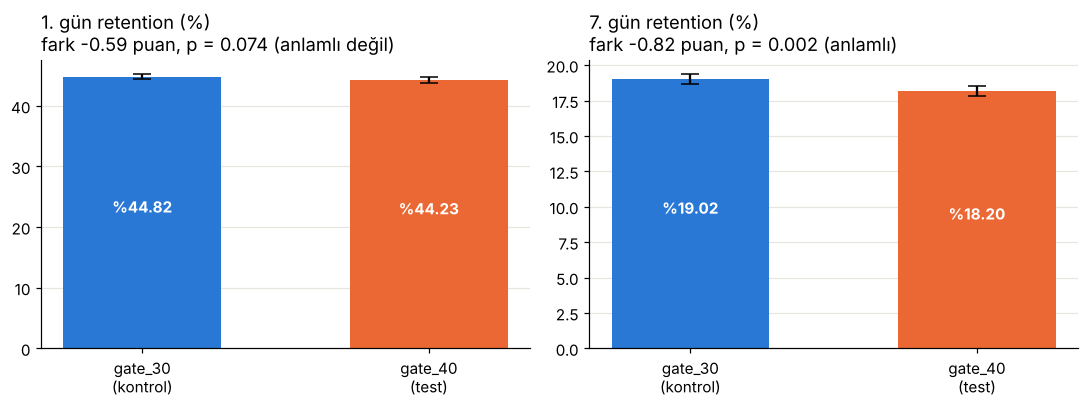

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, metrik, baslik in [(axes[0], "retention_1", "1. gün retention (%)"), (axes[1], "retention_7", "7. gün retention (%)")]:
    r = results[metrik]
    vals = [r["gate_30_%"], r["gate_40_%"]]
    se = [100 * np.sqrt(v / 100 * (1 - v / 100) / n) for v, n in zip(vals, [n30, n40])]
    ax.bar(["gate_30\n(kontrol)", "gate_40\n(test)"], vals, color=[BLUE, ORANGE], yerr=[1.96 * s for s in se], capsize=6, width=0.55)
    for i, v in enumerate(vals):
        ax.text(i, v / 2, f"%{v:.2f}", ha="center", color="white", fontweight="bold")
    durum = "anlamlı" if r["anlamli_bonferroni"] else "anlamlı değil"
    ax.set_title(f"{baslik}\nfark {r['fark_puan']:+.2f} puan, p = {r['p']:.3f} ({durum})")
    ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "01_retention_karsilastirma.png"); plt.show()

**Sonuç:**
- gate_40 grubunda 7. gün retention **0,82 puan daha düşük** (%19,02 → %18,20). Göreli olarak %4,3'lük bir kayıp.
- Fark **anlamlı** (p = 0,0016). Bonferroni eşiği olan 0,025'in de çok altında.
- Güven aralığı tamamen sıfırın altında: kayıp en az ~0,3, en fazla ~1,3 puan.
- Yani kapıyı 40. seviyeye taşımak, oyuncuların uzun vadede oyunda kalmasını **azaltıyor.** Ürün ekibinin beklentisinin tersi.

---
## 6. Bootstrap ile doğrulama

**Neden:** Z-testi büyük örneklemde güvenilir bir yaklaşımdır ama dağılım varsayımına dayanır. Bootstrap hiçbir dağılım varsayımı yapmadan aynı sonuca ulaşıp ulaşmadığımızı kontrol eder. Ayrıca yönetimin anlayacağı bir dilde sonuç verir: "gate_30'un daha iyi olma olasılığı yüzde kaç?"

**Nasıl:** Her grubu kendi içinden yerine koyarak 5.000 kez yeniden örnekliyoruz. Her örneklemde iki grubun retention farkını hesaplıyoruz. Bu 5.000 farkın dağılımı, gerçek farkın belirsizliğini gösterir.

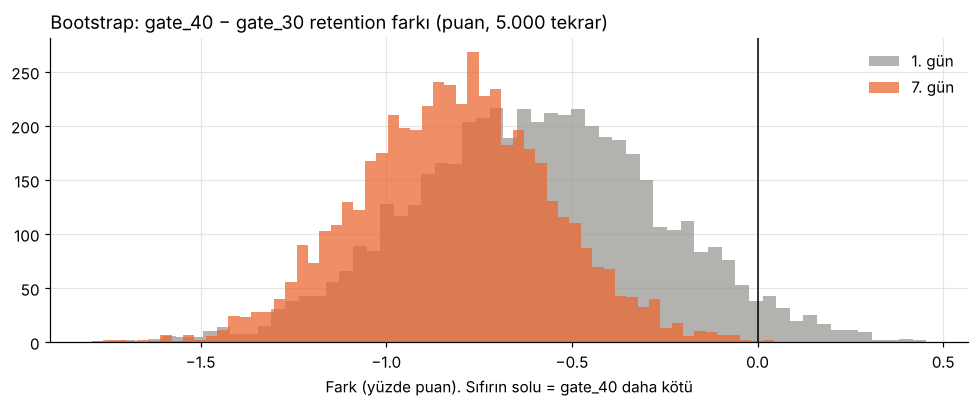

retention_1: gate_30'un daha iyi olma olasılığı %96.2, %95 GA [-1.25, 0.06]
retention_7: gate_30'un daha iyi olma olasılığı %99.9, %95 GA [-1.33, -0.30]


In [12]:
rng = np.random.default_rng(42)
B = 5000
boot = {}
for metrik in ["retention_1", "retention_7"]:
    a = df.loc[df.version == "gate_30", metrik].to_numpy()
    b = df.loc[df.version == "gate_40", metrik].to_numpy()
    # binom örnekleme, gözlem bazlı yeniden örneklemeyle aynı dağılımı verir ama çok daha hızlı
    fa = rng.binomial(len(a), a.mean(), B) / len(a)
    fb = rng.binomial(len(b), b.mean(), B) / len(b)
    boot[metrik] = 100 * (fb - fa)

fig, ax = plt.subplots(figsize=(9, 3.8))
for metrik, renk, ad in [("retention_1", GRAY, "1. gün"), ("retention_7", ORANGE, "7. gün")]:
    ax.hist(boot[metrik], bins=60, alpha=0.75, color=renk, label=ad)
ax.axvline(0, color="black", lw=1)
ax.set_title("Bootstrap: gate_40 − gate_30 retention farkı (puan, 5.000 tekrar)")
ax.set_xlabel("Fark (yüzde puan). Sıfırın solu = gate_40 daha kötü")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "02_bootstrap.png"); plt.show()

results["bootstrap"] = {}
for metrik in boot:
    olasilik = (boot[metrik] < 0).mean()
    ga = np.percentile(boot[metrik], [2.5, 97.5])
    results["bootstrap"][metrik] = {"gate_30_daha_iyi_olasilik_%": round(100 * olasilik, 1),
                                    "ga95": [round(ga[0], 2), round(ga[1], 2)]}
    print(f"{metrik}: gate_30'un daha iyi olma olasılığı %{100*olasilik:.1f}, %95 GA [{ga[0]:.2f}, {ga[1]:.2f}]")

**Sonuç:**
- Bootstrap, z-testiyle aynı sonucu veriyor. Güven aralıkları neredeyse aynı.
- 7. gün retention için gate_30'un daha iyi olma olasılığı **%99,9**. 1. gün için **%96**: yön aynı ama belirsizlik daha yüksek.

---
## 7. Oyun turu sayısı (engagement)

**Neden:** Retention düşerken oyuncular daha çok oynuyor olabilir mi? Ürün ekibinin beklentisi buydu: kapı geç gelirse oyuncu kesintisiz daha fazla oynar.

**Nasıl:** İlk 14 günde oynanan tur sayısı. Dağılım çok çarpık (çoğu oyuncu az, birkaçı çok oynuyor). Bu yüzden ortalama yerine medyana bakıyoruz ve **Mann-Whitney U testi** kullanıyoruz. Bu test dağılımın normal olmasını gerektirmez.

In [13]:
tur = df.groupby("version").sum_gamerounds.agg(ortalama="mean", medyan="median",
                                              ust_ceyrek=lambda s: s.quantile(0.75))
_, p_mw = stats.mannwhitneyu(df.loc[df.version == "gate_30", "sum_gamerounds"],
                             df.loc[df.version == "gate_40", "sum_gamerounds"], alternative="two-sided")
print(f"Mann-Whitney U p-değeri: {p_mw:.3f}")
results["engagement"] = {"medyan_30": float(tur.loc["gate_30", "medyan"]), "medyan_40": float(tur.loc["gate_40", "medyan"]),
                         "ortalama_30": round(tur.loc["gate_30", "ortalama"], 1), "ortalama_40": round(tur.loc["gate_40", "ortalama"], 1),
                         "mann_whitney_p": round(float(p_mw), 3)}
tur

Mann-Whitney U p-değeri: 0.051


,ortalama,medyan,ust_ceyrek
version,,,
gate_30,51.3421,17.0000,50.0000
gate_40,51.2988,16.0000,52.0000


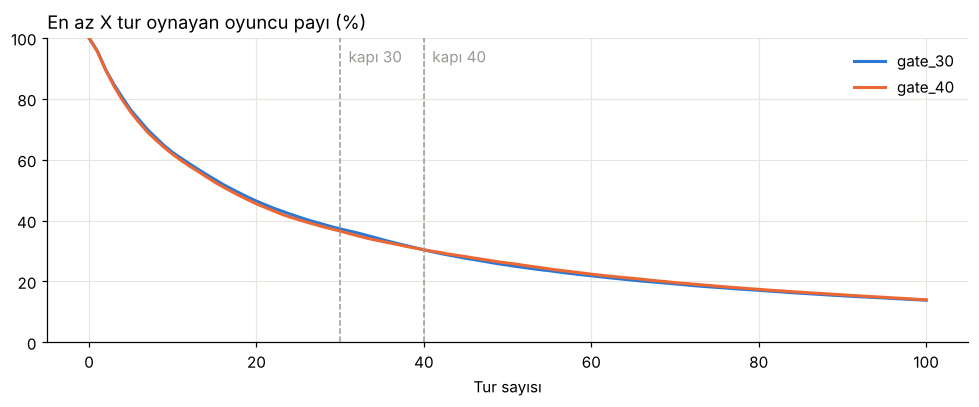

In [14]:
# Kaç oyuncu, kaç turda oyunu bıraktı? (hayatta kalma eğrisi)
esikler = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(9, 3.8))
for v in ["gate_30", "gate_40"]:
    s = df.loc[df.version == v, "sum_gamerounds"].to_numpy()
    ax.plot(esikler, [100 * (s >= e).mean() for e in esikler], color=RENK[v], lw=2, label=v)
for seviye in [30, 40]:
    ax.axvline(seviye, color=GRAY, ls="--", lw=1)
    ax.text(seviye + 1, 92, f"kapı {seviye}", color=GRAY)
ax.set_title("En az X tur oynayan oyuncu payı (%)")
ax.set_xlabel("Tur sayısı"); ax.set_ylim(0, 100); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_tur_hayatta_kalma.png"); plt.show()

**Sonuç:**
- Tur sayısında iki grup arasında anlamlı bir fark yok (medyan 17 ve 16, p = 0,05 civarında, sınırda).
- Eğrilerde iki grup neredeyse üst üste. Kapının yerini değiştirmek oyuncuların ilk 14 gündeki oyun miktarını belirgin şekilde artırmamış.
- Yani ürün ekibinin beklediği "daha çok oyun" etkisi gerçekleşmemiş, ama 7. gün retention kaybı gerçekleşmiş.

---
## 8. Keşifsel: kapıya ulaşan oyuncular

**Neden:** Kapı yalnızca 30 seviyeye ulaşan oyuncuları etkiler. Etkinin bu oyuncularda yoğunlaşıp yoğunlaşmadığını merak ediyoruz.

**Nasıl:** En az 30 tur oynayanlar ve 30'dan az oynayanlar için 7. gün retention farkı.

**Uyarı:** Bu analiz **nedensel değil, sadece keşifsel.** Tur sayısı deneyden etkilenen bir değişken. Oyuncuları deney sonrası davranışa göre gruplamak, iki grubu artık karşılaştırılabilir olmaktan çıkarır. Bu bölüm karar için kullanılmaz, sadece etkinin nerede oluştuğuna dair fikir verir.

In [15]:
df["oyuncu_tipi"] = np.where(df.sum_gamerounds >= 30, "30+ tur", "30'dan az tur")
kesif = df.pivot_table(index="oyuncu_tipi", columns="version", values="retention_7", aggfunc="mean") * 100
kesif["fark_puan"] = kesif.gate_40 - kesif.gate_30
kesif["oyuncu"] = df.oyuncu_tipi.value_counts()
results["kesifsel"] = {i: {"gate_30_%": round(r.gate_30, 2), "gate_40_%": round(r.gate_40, 2), "fark_puan": round(r.fark_puan, 2)}
                       for i, r in kesif.iterrows()}
kesif

version,gate_30,gate_40,fark_puan,oyuncu
oyuncu_tipi,,,,
30'dan az tur,4.2576,3.9306,-0.3270,56920
30+ tur,43.8727,43.0025,-0.8702,33268


**Sonuç:**
- Mutlak retention farkı, kapıya ulaşan oyuncularda (30+ tur) daha büyük: **−0,87 puan**. Kapıya ulaşmayanlarda **−0,33 puan**.
- Kapıya ulaşmayan oyuncular kapının yerinden etkilenmemeliydi. Bu gruptaki küçük fark, Bölüm 2'deki dengesizlikle tutarlı. Gruplar tam eşit oluşmamış olabilir.
- Yukarıdaki uyarı nedeniyle bu tablo bir kanıt değil. Etkinin büyük kısmının kapıya ulaşan oyuncularda oluştuğuna işaret ediyor, ama SRM sorunu çözülmeden kesin bir yorum yapılamaz.

---
## 9. İş etkisi

**Neden:** "0,82 puan" yönetim için soyut bir sayı. Bunu oyuncu sayısına çeviriyoruz.

**Nasıl:** Varsayım: oyun ayda 1 milyon yeni kurulum alıyor (gösterim amaçlı yuvarlak bir sayı; gerçek kurulum sayısıyla değiştirilmeli). Kayıp oyuncu = kurulum × retention farkı. Güven aralığının iki ucu da hesaplanıyor.

In [16]:
KURULUM = 1_000_000
r7 = results["retention_7"]
kayip = {"tahmin": -KURULUM * r7["fark_puan"] / 100,
         "en_az": -KURULUM * r7["ga95"][1] / 100,
         "en_fazla": -KURULUM * r7["ga95"][0] / 100}
results["is_etkisi"] = {"aylik_kurulum_varsayimi": KURULUM, **{k: int(round(v, -2)) for k, v in kayip.items()}}
print(f"Ayda {KURULUM:,} kurulumda, kapı 40'a taşınırsa 7. günde oyunda kalan oyuncu kaybı:")
print(f"  Tahmin: ~{kayip['tahmin']:,.0f} oyuncu  (%95 GA: {kayip['en_az']:,.0f} – {kayip['en_fazla']:,.0f})")

Ayda 1,000,000 kurulumda, kapı 40'a taşınırsa 7. günde oyunda kalan oyuncu kaybı:
  Tahmin: ~8,200 oyuncu  (%95 GA: 3,100 – 13,300)


**Sonuç:** Ayda 1 milyon kurulum alan bir oyun için kapıyı 40'a taşımak, her ay 7. günde oyunda kalan yaklaşık **8.200 oyuncu** kaybı demek (güven aralığı ~3.100 – ~13.300). Bu oyuncular, uzun vadede gelir getirecek kitlenin bir parçası.

---
## 10. Sonuç ve karar

| Metrik | gate_30 | gate_40 | Fark | p | Sonuç |
|---|---|---|---|---|---|
| 1. gün retention | %44,82 | %44,23 | −0,59 puan | 0,074 | Anlamlı değil |
| 7. gün retention | %19,02 | %18,20 | −0,82 puan | 0,002 | **Anlamlı kayıp** |
| Medyan tur sayısı | 17 | 16 | −1 | ~0,05 | Sınırda, pratikte fark yok |

### Karar
**Kapı 30. seviyede kalmalı.** Kapıyı 40'a taşımak 7. gün retention'ı anlamlı şekilde düşürüyor ve beklenen faydayı (daha çok oyun) sağlamıyor.

Olası bir açıklama: kapıdaki zorunlu bekleme, oyuncuya mola verdiriyor ve oyunu "tüketip sıkılmasını" geciktiriyor. Kapı geç gelince oyuncu ilk günlerde daha çok tüketiyor ve daha erken bırakıyor. Bu bir hipotez, ayrıca test edilmeli.

### Kararı vermeden önce
1. **SRM incelenmeli.** Grup büyüklükleri beklenenden farklı (p = 0,009) ve kapı öncesi davranışta da küçük bir dengesizlik var (p = 0,02). Atama ve kayıt sistemi kontrol edilmeli. Bir hata bulunursa deney düzeltilip tekrarlanmalı.
2. SRM'in açıklaması zararsız çıkarsa (ör. belirli bir günün kayıtları eksik ama iki gruba eşit dağılmış), mevcut sonuçla karar verilebilir.

### Sınırlılıklar
- Sadece 1. ve 7. gün retention var. Uzun vadeli (30 gün) retention ve gelir verisi yok.
- Satın alma (ödeme) verisi yok. Kapıyı geçmek için ödeme yapan oyuncu sayısı karar için önemli olurdu.
- Bölüm 8'deki alt grup analizi nedensel değil.

In [17]:
Path("reports/results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))
print("Sonuçlar reports/results.json dosyasına kaydedildi.")

Sonuçlar reports/results.json dosyasına kaydedildi.
